In [121]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit
import scipy.constants as pc
import astropy.units as u
from astropy.io import fits
import pandas as pd
import astropy
from astropy.coordinates import SkyCoord
from astropy.table import Table
from astropy.table import vstack
from astropy.cosmology import FlatLambdaCDM
from scipy.stats import ttest_rel
from scipy.stats import poisson
from scipy.stats import chi2
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import AutoMinorLocator
import os
from matplotlib.gridspec import GridSpec

from fitting_schechter_smf import schechter_function, _parse_err, fit_smf_mcmc, plotting

FIG_DIR = "/nvme/scratch/work/econnick"

DATA_PRODUCTS_PATH = "/nvme/scratch/work/econnick"

#DATA_INPUTS_PATH = "/raid/scratch/work/alberttg/Masters_project/Data_inputs"

VMAX_PATH = "/nvme/scratch/work/austind/EPOCHS-v2/data/UVLFs/Vmax_compl"

STEPHEN_DATA_PATH = "/nvme/scratch/work/econnick/stephenmwilkins_data"

COSMO = FlatLambdaCDM(H0=70, Om0=0.3)

In [122]:
def linear_to_log(values, upper_err, lower_err):

    log_values = np.log10(values)

    log_upper_err = np.log10(values + upper_err) - np.log10(values)

    log_lower_err = np.log10(values) - np.log10(values - lower_err)

    return log_values, log_upper_err, log_lower_err

In [123]:
def fits_table(file_path):
        # Open the FITS file
        with fits.open(file_path) as hdul:
            # Show the HDU structure
            # hdul.info()
            # Usually the table is in extension 1
            data = hdul[1].data

        # Convert to an Astropy Table
        tbl = Table(data)
        #print("Number of objects = ", len(tbl))

        # Print column names
        # print("\nColumns:")
        # print(tbl.colnames)

        return tbl

In [124]:
def read_tom_data(filename):
    
    path = os.path.join(STEPHEN_DATA_PATH, filename)
    colnames=['z', 'deltaz', 'log10Mstar', 'deltalog10Mstar', 'phi', 'phi_error_low', 'phi_error_upp', 'Medianlog10Mstar', 'AverageCompleteness', 'AverageContamination', 'NGal']

    tom_data = pd.read_csv(path, names=colnames, delimiter=' ', header=1, comment="#")
    redshift_tom = np.asarray(tom_data["z"], dtype=float)
    log_mass_tom = np.asarray(tom_data["log10Mstar"], dtype=float)
    log_mass_error_tom = np.asarray(tom_data["deltalog10Mstar"], dtype=float)
    smf_tom = np.asarray(tom_data["phi"], dtype=float)
    smf_lower_error_tom = np.asarray(tom_data["phi_error_low"], dtype=float)
    smf_upper_error_tom = np.asarray(tom_data["phi_error_upp"], dtype=float)
    

    nan_mask = smf_tom > smf_lower_error_tom
    redshift_tom = redshift_tom[nan_mask]
    log_mass_tom = log_mass_tom[nan_mask]
    log_mass_error_tom = log_mass_error_tom[nan_mask]
    smf_tom = smf_tom[nan_mask]
    smf_lower_error_tom = smf_lower_error_tom[nan_mask]
    smf_upper_error_tom = smf_upper_error_tom[nan_mask]


    log_smf_tom = np.log10(smf_tom)
    log_smf_upper_err_tom = np.log10(smf_tom + smf_upper_error_tom) - log_smf_tom
    log_smf_lower_err_tom = log_smf_tom - np.log10(smf_tom - smf_lower_error_tom)

    
    return redshift_tom, log_mass_tom, log_mass_error_tom, log_smf_tom, log_smf_lower_err_tom, log_smf_upper_err_tom

In [125]:
def read_stephenmwilkins_data(filename):
    """
    filename is f"z_{integer redshift}.txt"
    """

    path = os.path.join(STEPHEN_DATA_PATH, filename)

    stephen_data = np.genfromtxt(path, skip_header=1, delimiter=' ')

    mstar = stephen_data[:,0]
    phi = stephen_data[:,1]
    delta_phi = stephen_data[:,2]

    err_mask = (phi <= delta_phi)

    mstar = mstar[~err_mask]
    phi = phi[~err_mask]
    delta_phi = delta_phi[~err_mask]

    log_phi, log_phi_upper_err, log_phi_lower_err = linear_to_log(phi, delta_phi, delta_phi)

    return mstar, log_phi, log_phi_upper_err, log_phi_lower_err

In [126]:
def stephen_plotting(j, ax):
    """
    j is redshift bin number 0 - 5.
    ax is axes to plot on.
    """

    if j==0:
        stephen_file = "z_7.txt"
        stephen_file2 = None
    if j==1:
        stephen_file = "z_8.txt"
        stephen_file2 = None
    if j==2:
        stephen_file = "z_9.txt"
        stephen_file2 = None
    if j==3:
        stephen_file = "z_10.txt"
        stephen_file2 = "z_11.txt"
    if j==4:
        stephen_file = "z_12.txt"
        stephen_file2 = "z_13.txt"
    
    mstar_steve, smf_steve, smf_upp_err_steve, smf_low_err_steve = read_stephenmwilkins_data(stephen_file)

    x_range = np.linspace(mstar_steve.min(), mstar_steve.max(), len(mstar_steve))
    lower_bound = smf_steve - smf_low_err_steve
    upper_bound = smf_steve + smf_upp_err_steve

    ax.plot(mstar_steve, smf_steve,
            color='firebrick', alpha=0.8, ls='--', lw=1.5, label = 'Wilkins data')
    ax.fill_between(x_range, lower_bound, upper_bound, color="firebrick", alpha=0.3, ls='-', lw=3, label=r"1$\sigma$ Confidence")



    if stephen_file2 is not None:
        mstar_steve2, smf_steve2, smf_upp_err_steve2, smf_low_err_steve2 = read_stephenmwilkins_data(stephen_file2)

        x_range2 = np.linspace(mstar_steve2.min(), mstar_steve2.max(), len(mstar_steve2))
        lower_bound2 = smf_steve2 - smf_low_err_steve2
        upper_bound2 = smf_steve2 + smf_upp_err_steve2

        ax.plot(mstar_steve2, smf_steve2,
                color='firebrick', alpha=0.8, ls='--', lw=1.5, label = 'Wilkins data')
        ax.fill_between(x_range2, lower_bound2, upper_bound2, color="firebrick", alpha=0.3, ls='-', lw=3, label=r"1$\sigma$ Confidence")



In [127]:
def add_marginal_hists(ax, x, y, bins=40, size="15%", pad=0.1, color="gray"):
    """
    Add marginal histograms of x and y on top of and to the right of ax,
    without disturbing ax's existing content (scatter, legend, etc.).

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Axes to attach histograms to.
    x, y : array-like
        Data for the x and y histograms.
    bins : int
        Number of histogram bins.
    size : str
        Size of the marginal axes relative to ax (e.g. "15%").
    pad : float
        Padding between ax and the marginal axes.
    color : str
        Histogram color.

    Returns
    -------
    ax_histx, ax_histy : the two new marginal axes
    """
    divider = make_axes_locatable(ax)

    # Top histogram (x-axis distribution)
    ax_histx = divider.append_axes("top", size=size, pad=pad, sharex=ax)
    ax_histx.hist(x, bins=bins, color=color, edgecolor='0.2', linewidth=0.5)
    ax_histx.tick_params(axis="x", labelbottom=False)  # hide x labels (shared with ax)
    ax_histx.set_yticks([])
    for spine in ["top", "right", "left"]:
        ax_histx.spines[spine].set_visible(False)

    # Right histogram (y-axis distribution)
    ax_histy = divider.append_axes("right", size=size, pad=pad, sharey=ax)
    ax_histy.hist(y, bins=bins, orientation="horizontal", color=color, edgecolor='0.2', linewidth=0.5)
    ax_histy.tick_params(axis="y", labelleft=False)  # hide y labels (shared with ax)
    ax_histy.set_xticks([])
    for spine in ["top", "right", "bottom"]:
        ax_histy.spines[spine].set_visible(False)

    return ax_histx, ax_histy

In [128]:
def plot_binned_medians_for_distribution(
    ax, x, y,
    x_upper_err, x_lower_err, y_upper_err, y_lower_err,
    n_bins, bin_axis, bin_axis_name,
    marker="s", markersize=14, markeredgecolor="black",
    markeredgewidth=1.5, color="red", **errorbar_kwargs
):
    """
    Bin data along `bin_axis`, compute the median of x and y within each bin,
    and plot the medians on `ax` with error bars derived from per-point
    error arrays. Marker style: thick-edged star. Not defined bin widths,
    instead displays the distribution of points. Is a bit dodgy.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Axes to plot on (existing content is preserved).
    x, y : array-like
        Data points.
    x_upper_err, x_lower_err, y_upper_err, y_lower_err : array-like
        Per-point asymmetric errors, same length as x/y.
    n_bins : int or array-like
        Desired number of bins, or explicit bin edges. If an int, it will
        be reduced automatically (see `min_points_per_bin`) and bin edges
        are chosen so each bin contains roughly equal numbers of points.
        If array-like, used as explicit bin edges (no automatic adjustment).
    bin_axis : {"x", "y"}
        Which variable to bin on.
    bin_axis_name:
        For the label on the median of binned points.
    marker, markersize, markeredgecolor, markeredgewidth, color :
        Passed to ax.errorbar for marker styling.
    **errorbar_kwargs :
        Any additional kwargs forwarded to ax.errorbar.

    Returns
    -------
    bin_x, bin_y, xerr, yerr : ndarrays
        The computed bin medians and their [lower, upper] error arrays
        (xerr and yerr have shape (2, n_bins)).
    """
    x = np.asarray(x)
    y = np.asarray(y)

    x_upper_err = np.zeros_like(x) if x_upper_err is None else np.asarray(x_upper_err)
    x_lower_err = np.zeros_like(x) if x_lower_err is None else np.asarray(x_lower_err)

    y_upper_err = np.zeros_like(y) if y_upper_err is None else np.asarray(y_upper_err)
    y_lower_err = np.zeros_like(y) if y_lower_err is None else np.asarray(y_lower_err)

    bin_data = x if bin_axis == "x" else y

    if np.isscalar(n_bins):
        n_data = len(bin_data)
        # Equal-count (quantile) bin edges, so each bin gets ~n_data/n_bins points
        sorted_data = np.sort(bin_data)
        quantile_positions = np.linspace(0, n_data - 1, n_bins + 1)
        edges = np.interp(quantile_positions, np.arange(n_data), sorted_data)
        # Guard against duplicate edges (e.g. many repeated values)
        edges = np.unique(edges)
        n_bins = len(edges) - 1
    else:
        edges = np.asarray(n_bins)
        n_bins = len(edges) - 1

    bin_idx = np.digitize(bin_data, edges) - 1
    bin_idx = np.clip(bin_idx, 0, n_bins - 1)  # ensure max value falls in last bin


    def bootstrap_median_errors(values, n_boot=5000, random_state=None):
        """
        Bootstrap estimate of asymmetric uncertainty on the median.

        Returns
        -------
        median, upper_err, lower_err
        """
        values = np.asarray(values)
        rng = np.random.default_rng(random_state)

        n = len(values)

        boot = np.empty(n_boot)

        for i in range(n_boot):
            sample = rng.choice(values, size=n, replace=True)
            boot[i] = np.median(sample)

        median = np.median(values)

        lo, hi = np.percentile(boot, [16, 84])

        return median, hi - median, median - lo


    bin_x, bin_y = [], []
    xerr_lo, xerr_hi = [], []
    yerr_lo, yerr_hi = [], []

    for i in range(n_bins):
        mask = bin_idx == i
        n = mask.sum()

        x_med, x_hi, x_lo = bootstrap_median_errors(x[mask])
        y_med, y_hi, y_lo = bootstrap_median_errors(y[mask])

        bin_x.append(x_med)
        xerr_lo.append(x_lo)
        xerr_hi.append(x_hi)

        bin_y.append(y_med)
        yerr_lo.append(y_lo)
        yerr_hi.append(y_hi)
    

    bin_x = np.array(bin_x)
    bin_y = np.array(bin_y)
    xerr = np.array([xerr_lo, xerr_hi])
    yerr = np.array([yerr_lo, yerr_hi])

    ax.errorbar(
        bin_x, bin_y, xerr=xerr, yerr=yerr,
        fmt=marker, markersize=markersize,
        markeredgecolor=markeredgecolor, markeredgewidth=markeredgewidth,
        color=color, linestyle="none", **errorbar_kwargs,
        label=f"Median of binned {bin_axis_name}", zorder=3
    )

    return bin_x, bin_y, xerr, yerr

In [129]:
def redshift_bins(redshifts, y_values, ax, marker_style, marker_size, colour, edgecolor='black', edgewidth=1):
    """
    Bin the data by redshift and compute the median and use IQR for the errors, for each bin.

    Parameters
    ----------
    redshifts : array-like
        The redshift values.
    y_values : array-like
        The corresponding y-values to compute statistics on.
    ax : matplotlib.axes.Axes
        The axes on which to plot the binned data.
    marker_style : str
        Square or diamond or circle points for the plot.
    marker_size : float
        Size of the points for the plot.
    colour : str
        Color of the points for the plot.
    """
    bins = [[6.5, 7.5], [7.5, 8.5], [8.5, 9.5], [9.5, 10.5], [10.5, 11.5], [11.5, 13.5]]
    # We've set z=6.5 as the minimum and the highest well-measured redshift galaxies at 13.5.

    bin_centers = []
    medians = []
    upper_errors = []
    lower_errors = []

    for i in range(len(bins)):
        bin_mask = (redshifts >= bins[i][0]) & (redshifts < bins[i][1])
        bin_redshifts = redshifts[bin_mask]
        bin_y_values = y_values[bin_mask]

        
        median = np.median(bin_y_values)
        upper_err = np.percentile(bin_y_values, 84) - median
        lower_err = median - np.percentile(bin_y_values, 16)
        bin_center = np.median(bins[i])

        bin_centers.append(bin_center)
        medians.append(median)
        upper_errors.append(upper_err)
        lower_errors.append(lower_err)

    ax.errorbar(bin_centers, medians, yerr=[lower_errors, upper_errors], 
                fmt=marker_style, markersize=marker_size,
                markeredgecolor=edgecolor, markeredgewidth=edgewidth,
                color=colour, linestyle="none",
                label=f"Median of binned redshifts", zorder=3
            )
    
    return bin_centers, medians, upper_errors, lower_errors

In [130]:
def plot_median_bins(x_values, y_values, n_bins, binned_axis_name, ax, marker_style, marker_size, colour):
    """
    Bin the data by redshift and compute the median and 16th and 84th percentiles for each bin.
    Plots the median values with error bars on the provided axes.

    Parameters
    ----------
    x_values : array-like
        The x-values to bin.
    y_values : array-like
        The corresponding y-values to compute statistics on.
    n_bins : int
        The number of bins to use for binning the data.
    ax : matplotlib.axes.Axes
        The axes on which to plot the binned data.
    marker_style : str
        Square or diamond or circle points for the plot.
    marker_size : float
        Size of the points for the plot.
    colour : str
        Color of the points for the plot.
    """
    bins = np.linspace(x_values.min(), x_values.max(), n_bins + 1)

    bins = [[bins[i], bins[i + 1]] for i in range(len(bins) - 1)]

    bin_centers = []
    medians = []
    upper_errors = []
    lower_errors = []

    for i in range(len(bins)):
        bin_mask = (x_values >= bins[i][0]) & (x_values < bins[i][1])
        bin_x_values = x_values[bin_mask]
        bin_y_values = y_values[bin_mask]

        
        median = np.median(bin_y_values)
        upper_err = np.percentile(bin_y_values, 84) - median
        lower_err = median - np.percentile(bin_y_values, 16)
        bin_center = np.median(bins[i])

        bin_centers.append(bin_center)
        medians.append(median)
        upper_errors.append(upper_err)
        lower_errors.append(lower_err)

    ax.errorbar(bin_centers, medians, yerr=[lower_errors, upper_errors], 
                fmt=marker_style, markersize=marker_size,
                markeredgecolor='black', markeredgewidth=1,
                color=colour, linestyle="none",
                label=f"Median of binned {binned_axis_name}", zorder=3
            )
    
    return bin_centers, medians, upper_errors, lower_errors

In [131]:
def open_catalogue_data(path, gold_path):
  """
  Reads in a catalogue of data from a FITS file and returns the data as an Astropy Table.
  """
  h = fits.open(gold_path)
  gold_sample = Table.read(gold_path, hdu = 1)

  
  hdul = fits.open(path)
  hdu_names = [hdu.name for hdu in hdul]

  # sex_cat = [hdu for hdu, name in zip(hdul, hdu_names) if name == "OBJECTS"][0]
    
  # EPOCHS series (Conselice+24, Adams+24, Austin+25, Harvey+25)

  sex_tab = Table.read(path, hdu = "OBJECTS")
  sex_tab_colnames = sex_tab.colnames
  # print(sex_tab_colnames)
  # sky position (Ra = ALPHA_J2000, Dec = DELTA_J2000)
  # flux columns: FLUX_APER_{band}_aper_corr_Jy [Jy]
  # flux error columns: FLUXERR_APER_{band}_loc_depth_5pc_Jy [Jy]

  bagpipes_zfix = Table.read(path, hdu = "BAGPIPES_SFH_CONT_BURSTY_ZEAZYSFHZBLUEAGN_3.0,10.0MYR_CALZETTI_LOG_10_Z_LOG_10_BPASS_ZFIX")
  # ext 3

  bagpipes_zgauss = Table.read(path, hdu = "BAGPIPES_SFH_CONT_BURSTY_ZEAZYSFHZBLUEAGN_3.0,10.0MYR_CALZETTI_LOG_10_Z_LOG_10_BPASS_ZGAUSS_3.0SIG")
  # ext 4

  selection_tab = Table.read(path, hdu = "SELECTION")

  return sex_tab, bagpipes_zfix, bagpipes_zgauss, selection_tab, gold_sample

In [132]:
def masked_table(sex_tab, bagpipes_zfix, bagpipes_zgauss, selection_tab, gold_sample):
    """
    Filtered zgauss table for galaxies with z >=6.5.
    Found the corresponding galaxy ids in zfix.
    Added the zgauss redshift error values to the zfix table.
    Highlight LRDs.
    Remove brown dwarfs.
    """
    # --------------- Cross matching zfix to all other tables --------------
    ids = bagpipes_zfix["UNIQUE_ID"].data

    bagpipes_zgauss = bagpipes_zgauss[np.isin(bagpipes_zgauss["UNIQUE_ID"], ids)]
    sex_tab = sex_tab[np.isin(sex_tab["UNIQUE_ID"], ids)]
    selection_tab = selection_tab[np.isin(selection_tab["UNIQUE_ID"], ids)]

    # --------------- Selecting high redshift galaxies ---------------
    z_mask = 6.5 <= bagpipes_zfix["input_redshift"].data

    zfix_sample = bagpipes_zfix[z_mask]
    # Now our sample is filtered for redshift >= 6.5
    bagpipes_zgauss = bagpipes_zgauss[z_mask]
    selection_tab = selection_tab[z_mask]
    sex_tab = sex_tab[z_mask]

    print("Check inital length: ", len(zfix_sample))

    # ----------------- select brown dwarfs ------------------
    brown_dwarf_mask = selection_tab["dchi2_EAZY_sfhz_blue_agn>0.0_F444W_bd_0.32as"] # These are brown dwarfs
    selection_tab = selection_tab[~brown_dwarf_mask] # We dont want BDs

    # selection_tab_ids = selection_tab["UNIQUE_ID"].data

    # zfix_sample = zfix_sample[np.isin(zfix_sample["UNIQUE_ID"].data, selection_tab_ids)]
    zfix_sample = zfix_sample[~brown_dwarf_mask]
    bagpipes_zgauss = bagpipes_zgauss[~brown_dwarf_mask]
    sex_tab = sex_tab[~brown_dwarf_mask]

    print("Check length after filtering out brown dwarfs: ", len(zfix_sample))


    zfix_sample["photo_z"] = np.zeros(len(zfix_sample), dtype=float)
    zfix_sample["photo_z_lower_err"] = np.zeros(len(zfix_sample), dtype=float)
    zfix_sample["photo_z_upper_err"] = np.zeros(len(zfix_sample), dtype=float)
    zfix_sample["is_LRD"] = np.zeros(len(zfix_sample), dtype=bool)
    zfix_sample["ext_src_corr_0.32as_F444W"] = np.zeros(len(zfix_sample), dtype=float)
    # We want a column for photo_z in the zfix table to store the zgauss redshift values.
    # And a column for is_LRD to store the selection results.

    for i in range(len(zfix_sample)):

        id = zfix_sample["UNIQUE_ID"][i]

        # ----------------------------- Data from zgauss into zfix table -----------------------------
        z_50 = bagpipes_zgauss["redshift_50"][np.where(id == bagpipes_zgauss["UNIQUE_ID"].data)[0][0]]
        # Getting zgauss photo z into z fix table
        z_84 = bagpipes_zgauss["redshift_84"][np.where(id == bagpipes_zgauss["UNIQUE_ID"].data)[0][0]]
        z_16 = bagpipes_zgauss["redshift_16"][np.where(id == bagpipes_zgauss["UNIQUE_ID"].data)[0][0]]
        # Using zgauss errors but plotting zfix redshift values.
        zfix_sample["photo_z_lower_err"][i] = z_50 - z_16
        zfix_sample["photo_z_upper_err"][i] = z_84 - z_50

        # ------------------------------ Data from selection into zfix table --------------------------
        # ------------ highlight LRDs -------------
        if selection_tab["Kokorev+24_LRD_red2_0.32as"][np.where(id == selection_tab["UNIQUE_ID"].data)[0]] & \
            selection_tab["compact_F444W_r=0.32/0.16as<1.10*psf"][np.where(id == selection_tab["UNIQUE_ID"].data)[0]] == True:

            is_LRD = True
        else:
            is_LRD = False

        zfix_sample["is_LRD"][i] = is_LRD

        # ------------------------------- Data from objects into zfix table ----------------------------
        # ------------ kron aperture correction -------------
        corr = sex_tab["ext_src_corr_0.32as_F444W"][np.where(id == sex_tab["UNIQUE_ID"].data)[0][0]]

        zfix_sample["ext_src_corr_0.32as_F444W"][i] = corr

        zfix_sample["stellar_mass_50"][i] = zfix_sample["stellar_mass_50"][i] + np.log10(corr)
        zfix_sample["stellar_mass_16"][i] = zfix_sample["stellar_mass_16"][i] + np.log10(corr)
        zfix_sample["stellar_mass_84"][i] = zfix_sample["stellar_mass_84"][i] + np.log10(corr)

    LRD_mask = zfix_sample["is_LRD"].data == True
    print("Number of LRDs in our sample = ", np.sum(LRD_mask))


    # zfix_sample is ready and has all relevant info
    # -------------------------------- Filtering further by only including galaxies in the gold sample ---------------------------------

    zfix_survey_id = np.asarray(zfix_sample["#ID"].data, dtype="int")
    zfix_surveys = np.asarray(zfix_sample["SURVEY"].data, dtype="str")

    gold_survey_id = np.asarray(gold_sample["SURVEY_ID"].data, dtype="int")
    gold_surveys = np.asarray(gold_sample["SURVEY"].data, dtype="str")

    
    # Create a dictionary keyed by (SURVEY_ID, SURVEY), mapped to EPOCHS_DR2_gold, for each row in gold_sample
    mapping = {
        (int(row["SURVEY_ID"]), str(row["SURVEY"]).strip()): float(row["EPOCHS_DR2_gold"])
        for row in gold_sample
    }

    # Look up each sample galaxy using both ID and SURVEY
    # zip pairs the elements at corresponding positions
    # mapping.get acquires the EPOCHS_DR2_gold value when the pair (uid, survey) is satisifed, but returns False when this fails
    is_gold = np.array( [ mapping.get((int(uid), str(survey).strip()), False) for uid, survey in zip(zfix_survey_id, zfix_surveys) ], dtype=bool)

    zfix_sample["EPOCHS_DR2_gold"] = is_gold

    # ----------------------- Filtering further by removing diffraction spikes and v_max completeness issues ----------------------------

    diffraction_spike_mask = np.isin(zfix_sample["UNIQUE_ID"], [1400, 250737, 512674, 704035, 704455, 886995])
    
    zfix_sample = zfix_sample[~diffraction_spike_mask]

    print("Check length after filtering out diffraction spikes: ", len(zfix_sample))
    
    v_max_completeness_mask = np.isin(zfix_sample["UNIQUE_ID"], [139997, 151269, 158012, 150971, 163814, 146613, 97516])

    zfix_sample = zfix_sample[~v_max_completeness_mask]

    print("No of gold galaxies: ", np.sum(zfix_sample["EPOCHS_DR2_gold"].data == True))

    return zfix_sample

In [133]:
def plot_stellar_mass_vs_redshift(sample_table):
    """
    Shows survey by colour and shape.
    """

    log_stellar_mass_Q16 = sample_table["stellar_mass_16"]
    log_stellar_mass_Q50 = sample_table["stellar_mass_50"]
    log_stellar_mass_Q84 = sample_table["stellar_mass_84"]

    log_stellar_mass_upper_err = log_stellar_mass_Q84 - log_stellar_mass_Q50
    log_stellar_mass_lower_err = log_stellar_mass_Q50 - log_stellar_mass_Q16

    spec_z = sample_table["input_redshift"]

    fig, ax = plt.subplots(figsize=(10, 10))

    # --------------------------- Colouring and marker styles for each survey ----------------------------
    survey = np.asarray(sample_table["SURVEY"].data, dtype=str)
    south = np.asarray(["JADES-DR3-GS-East", "JADES-DR3-GS-North", "JADES-DR3-GS-South", "JADES-DR3-GS-West", "NGDEEP"], dtype=str)
    north = np.asarray(["JADES-DR3-GN-Parallel", "JADES-DR3-GN-Medium", "JADES-DR3-GN-Deep"], dtype=str)
    uds =  np.asarray(["PRIMER-UDS"], dtype=str)
    cosmos = np.asarray(["PRIMER-COSMOS"], dtype=str)
    ceers = np.asarray(["CEERSP1", "CEERSP2", "CEERSP3", "CEERSP4", "CEERSP5", "CEERSP6", "CEERSP7", "CEERSP8", "CEERSP9", "CEERSP10"], dtype=str)
    nep = np.asarray(["NEP-1", "NEP-2", "NEP-3", "NEP-4"], dtype=str)

    colours = np.empty(len(survey), dtype=object)
    marker_styles = np.empty(len(survey), dtype='<U1')  # Use a string type for marker styles
    for i, s in enumerate(survey):
        if s in south:
            colours[i] = 'tab:orange'
            marker_styles[i] = 'o'
        if s in north:
            colours[i] = 'tab:cyan'
            marker_styles[i] = 'd'
        if s in ceers:
            colours[i] = 'tab:purple'
            marker_styles[i] = 'p'
        if s in uds:
            colours[i] = 'tab:blue'
            marker_styles[i] = '^'
        if s in cosmos:
            colours[i] = 'tab:red'
            marker_styles[i] = '*'
        if s in nep:
            colours[i] = 'tab:green'
            marker_styles[i] = 's'

    legend_elements = [
            Line2D([0], [0], marker='o', color='w',
                label='GOODS-South',
                markerfacecolor='tab:orange',
                markeredgecolor='0.3',
                linewidth=0.5,
                markersize=7),

            Line2D([0], [0], marker='o', color='w',
                label='GOODS-North',
                markerfacecolor='tab:cyan',
                markeredgecolor='0.3',
                linewidth=0.5,
                markersize=7),
                
            Line2D([0], [0], marker='p', color='w',
                label='CEERS',
                markerfacecolor='tab:purple',
                markeredgecolor='0.3',
                linewidth=0.5,
                markersize=7),
                    
            Line2D([0], [0], marker='^', color='w',
                label='PRIMER-UDS',
                markerfacecolor='tab:blue',
                markeredgecolor='0.3',
                linewidth=0.5,
                markersize=7),
                    
            Line2D([0], [0], marker='s', color='w',
                label='NEP',
                markerfacecolor='tab:green',
                markeredgecolor='0.3',
                linewidth=0.5,
                markersize=7),
                    
            Line2D([0], [0], marker='*', color='w',
                label='PRIMER-COSMOS',
                markerfacecolor='tab:red',
                markeredgecolor='0.3',
                linewidth=0.5,
                markersize=7)    ]

    # plt.errorbar(spec_z, log_stellar_mass_Q50, yerr=[log_stellar_mass_lower_err, log_stellar_mass_upper_err], fmt='o', ecolor='black', alpha=0.5)
        
    for xi, yi, colour, style in zip(spec_z, log_stellar_mass_Q50, colours, marker_styles):
        
        plt.scatter(xi, yi, c=colour, marker=style, alpha=0.7, s=20)
    #--------------------------------------------------------------------

    plt.xlabel(r'Redshift $z_{spec}$', fontsize=18)
    plt.ylabel(r'Log Stellar Mass $log_{10}(M_*/M_\odot)$', fontsize=18)
    plt.grid(True)

    # plt.hexbin(spec_z, log_stellar_mass_Q50, cmap='Blues', alpha=1.0)

    ax.tick_params(
            axis="both",
            which="major",
            labelsize=14,
            length=8,
            width=1.5,
            direction="in",
            top=True,
            right=True
        )
    
    ax.xaxis.set_minor_locator(AutoMinorLocator(5))
    ax.yaxis.set_minor_locator(AutoMinorLocator(5))

    ax.tick_params(
        axis="both",
        which="minor",
        length=4,
        width=1,
        direction="in",
        top=True,
        right=True
    )

    add_marginal_hists(ax, x=spec_z, y=log_stellar_mass_Q50, bins=30, size="15%", pad=0.1, color="gray")

    redshift_bins(spec_z, log_stellar_mass_Q50, ax, "s", 10, "black")

    line_legend = ax.legend(loc='lower right', fontsize=15)
    ax.add_artist(line_legend)

    ax.legend(handles=legend_elements, title="Survey", loc='upper right', fontsize=13, title_fontsize=14, frameon=True, edgecolor='black', facecolor='white')

    fig_path = os.path.join(FIG_DIR, "stellar_mass_vs_redshift.png")
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

In [134]:
def plot_stellar_mass_vs_redshift_show_LRDs(sample_table):
    """
    Shows LRDs.
    """

    log_stellar_mass_Q16 = sample_table["stellar_mass_16"]
    log_stellar_mass_Q50 = sample_table["stellar_mass_50"]
    log_stellar_mass_Q84 = sample_table["stellar_mass_84"]

    log_stellar_mass_upper_err = log_stellar_mass_Q84 - log_stellar_mass_Q50
    log_stellar_mass_lower_err = log_stellar_mass_Q50 - log_stellar_mass_Q16

    spec_z = sample_table["input_redshift"]

    # -------------------------- Not colouring by survey, now showcasing LRDS -----------------------------
    fig, ax = plt.subplots(figsize=(10, 10))

    # --------------------------- Colouring and marker styles for each survey ----------------------------
    is_LRD = np.asarray(sample_table["is_LRD"].data, dtype=bool)
    gold = np.asarray(sample_table["EPOCHS_DR2_gold"].data, dtype=bool)
    
    colours = np.empty(len(is_LRD), dtype=object)
    marker_styles = np.empty(len(is_LRD), dtype='<U1')  # Use a string type for marker styles
    # z_order = np.empty(len(is_LRD), dtype='<U1')

    for i in range(len(is_LRD)):
        if is_LRD[i]:
            colours[i] = 'tab:red'
            marker_styles[i] = 'o'

        elif gold[i]:
            colours[i] = 'goldenrod'
            marker_styles[i] = 'd'
            
        else:
            colours[i] = 'tab:blue'
            marker_styles[i] = 's'
            

    legend_elements = [
            Line2D([0], [0], marker='o', color='w',
                label='LRD',
                markerfacecolor='tab:red',
                markeredgecolor='0.7',
                linewidth=0.5,
                markersize=7),

            Line2D([0], [0], marker='d', color='w',
                label='Gold sample',
                markerfacecolor='goldenrod',
                markeredgecolor='0.7',
                linewidth=0.5,
                markersize=7),

            Line2D([0], [0], marker='s', color='w',
                label='Galaxy',
                markerfacecolor='tab:blue',
                markeredgecolor='0.3',
                linewidth=0.5,
                markersize=7),    
            ]

    # plt.errorbar(spec_z, log_stellar_mass_Q50, yerr=[log_stellar_mass_lower_err, log_stellar_mass_upper_err], fmt='o', ecolor='black', alpha=0.5)
        
    for xi, yi, colour, style in zip(spec_z, log_stellar_mass_Q50, colours, marker_styles):
        
        plt.scatter(xi, yi, c=colour, marker=style, alpha=0.7, s=20)
    #--------------------------------------------------------------------

    plt.xlabel(r'Redshift $z_{spec}$', fontsize=18)
    plt.ylabel(r'Log Stellar Mass $log_{10}(M_*/M_\odot)$', fontsize=18)
    plt.grid(True)

    # plt.hexbin(spec_z, log_stellar_mass_Q50, cmap='Blues', alpha=1.0)

    ax.tick_params(
            axis="both",
            which="major",
            labelsize=14,
            length=8,
            width=1.5,
            direction="in",
            top=True,
            right=True
        )
    
    ax.xaxis.set_minor_locator(AutoMinorLocator(5))
    ax.yaxis.set_minor_locator(AutoMinorLocator(5))

    ax.tick_params(
        axis="both",
        which="minor",
        length=4,
        width=1,
        direction="in",
        top=True,
        right=True
    )

    add_marginal_hists(ax, x=spec_z, y=log_stellar_mass_Q50, bins=30, size="15%", pad=0.1, color="gray")

    redshift_bins(spec_z, log_stellar_mass_Q50, ax, "s", 10, "black")

    line_legend = ax.legend(loc='lower right', fontsize=15)
    ax.add_artist(line_legend)

    ax.legend(handles=legend_elements, loc='upper right', fontsize=13, frameon=True, edgecolor='black', facecolor='white')

    fig_path = os.path.join(FIG_DIR, "stellar_mass_vs_redshift_LRDs.png")
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

In [135]:
def plot_stellar_mass_vs_M_UV(sample_table):

    z_bins = [[6.5, 7.5], [7.5, 8.5], [8.5, 9.5], [9.5, 10.5], [10.5, 11.5], [11.5, 13.5]]
    # Only going up to z=12.5 because there are very few galaxies at higher redshifts, and the bins would be empty.

    #Creating a figure of 8 subplots in 2x4 grid for each galaxy
    fig, axes = plt.subplots(2, 3, figsize=(20,10), constrained_layout=False)
    axes = axes.ravel()

    for i, z_bin in enumerate(z_bins):
        bin_mask = (sample_table["input_redshift"] >= z_bin[0]) & (sample_table["input_redshift"] < z_bin[1])
        bin_sample = sample_table[bin_mask]

        if len(bin_sample) > 5:
            print(f"Redshift bin {z_bin}: {len(bin_sample)} galaxies")

        ax = axes[i]

        log_stellar_mass_Q16 = bin_sample["stellar_mass_16"]
        log_stellar_mass_Q50 = bin_sample["stellar_mass_50"]
        log_stellar_mass_Q84 = bin_sample["stellar_mass_84"]

        log_stellar_mass_upper_err = log_stellar_mass_Q84 - log_stellar_mass_Q50
        log_stellar_mass_lower_err = log_stellar_mass_Q50 - log_stellar_mass_Q16

        M_uv_Q16 = bin_sample["M_UV_16"]
        M_uv_Q50 = bin_sample["M_UV_50"]
        M_uv_Q84 = bin_sample["M_UV_84"]

        # plt.errorbar(redshift, log_stellar_mass_Q50, yerr=[log_stellar_mass_lower_err, log_stellar_mass_upper_err], fmt='o', ecolor='black', alpha=0.5)
        # plt.scatter(M_uv_Q50, log_stellar_mass_Q50, color='steelblue', alpha=0.6)

        ax.set_xlabel(r'M$_{UV}$', fontsize=18)
        ax.set_ylabel(r'Log Stellar Mass $log_{10}(M_*/M_\odot)$', fontsize=18)
        ax.grid(True)

        ax.hexbin(M_uv_Q50, log_stellar_mass_Q50, cmap='Blues', alpha=1.0)

        ax.tick_params(
                axis="both",
                which="major",
                labelsize=14,
                length=8,
                width=1.5,
                direction="in",
                top=True,
                right=True
            )
    
        ax.xaxis.set_minor_locator(AutoMinorLocator(5))
        ax.yaxis.set_minor_locator(AutoMinorLocator(5))

        ax.tick_params(
            axis="both",
            which="minor",
            length=4,
            width=1,
            direction="in",
            top=True,
            right=True
        )

        add_marginal_hists(ax, x=M_uv_Q50, y=log_stellar_mass_Q50, bins=30, size="15%", pad=0.1, color="steelblue")

        plot_median_bins(
            x_values=M_uv_Q50, y_values=log_stellar_mass_Q50, n_bins=8, binned_axis_name="M$_{UV}$",
            ax=ax, marker_style="s", marker_size=10, colour="orange"
        )

        ax.legend(loc="lower left", fontsize=15)

        legend_text = f"Redshift bin: {z_bin[0]} - {z_bin[1]}"
        ax.text(0.05, 0.95, legend_text, transform=ax.transAxes, fontsize=15, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
    
    plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, "stellar_mass_vs_M_UV.png")
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

In [136]:
def load_V_max_values(sample_table):
    """
    Makes a Vmax column in our sample table, loads in the values Duncan calculated.
    The survey_id and survey have to match for a galaxy across the tables (as survey_id has degeneracies across surveys).
    """
    sample_survey_id = np.asarray(sample_table["#ID"].data, dtype=int)
    sample_surveys = np.asarray(sample_table["SURVEY"].data, dtype=str)

    z_bin = [['6.50', '7.50'], ['7.50', '8.50'], ['8.50', '9.50'], ['9.50', '10.50'], ['10.50', '11.50'], ['11.50', '13.50']]
    
     # Collect the data from all Vmax files
    vmax_data = [] # This is a table

    for z in z_bin:

        path = (f"{z[0]}<z<{z[1]}_EPOCHS_good_area_depth_scaled_split_region.ecsv")

        data = pd.read_csv(os.path.join(VMAX_PATH, path), delimiter=r"\s+", comment="#")

        vmax_data.append(data[["ID", "survey", "Vmax_compl"]])

    vmax_data = pd.concat(vmax_data, ignore_index=True)

    # Create a dictionary keyed by (ID, survey), mapped to Vmax_compl, for each row in vmax_data
    mapping = {
        (int(row.ID), str(row.survey).strip()): float(row.Vmax_compl)
        for row in vmax_data.itertuples(index=False)
    }
    # index=False means the DataFrame's row index is not included in each returned object. This is exclusive to pandas.

    # Look up each sample galaxy using BOTH ID and survey
    # zip pairs the elements at corresponding positions
    # mapping.get acquires the vmax_compl value when the pair is satisifed, but returns np.nan when this fails
    vmax_values = np.array( [ mapping.get((int(uid), str(survey).strip()), np.nan) for uid, survey in zip(sample_survey_id, sample_surveys) ], dtype=float)

    # Add the results to the sample table
    sample_table["Vmax"] = vmax_values

    return sample_table

In [137]:
def poisson_interval(k, alpha=0.05):
                """Compute the Poisson confidence interval for a count using the
                chi-squared method.

                Parameters
                ----------
                k : `int`
                    Observed count.
                alpha : `float`, optional
                    Significance level (e.g. 0.05 for a 95% interval). Default is 0.05.

                Returns
                -------
                `tuple` of `float`
                    ``(low, high)`` confidence interval bounds on the Poisson rate.

                Notes
                -----
                Uses `scipy.stats.chi2`. Adapted from
                https://stackoverflow.com/questions/14813530/poisson-confidence-interval-with-numpy
                """
                low, high = (
                    chi2.ppf(alpha / 2.0, 2 * k) / 2,
                    chi2.ppf(1.0 - alpha / 2.0, (2 * k) + 2) / 2,
                )
                if k == 0:
                    low = 0.0
                return low, high

In [ ]:
def plot_Muv_vs_Vmax(sample_table):
    """
    Plot M_UV vs V_max for each redshift and mass bin in order to identify any outliers.

    """
    ids = sample_table["UNIQUE_ID"].data
    
    redshift = sample_table["input_redshift"].data

    mass = sample_table["stellar_mass_50"].data

    M_uv = sample_table["M_UV_50"].data

    M_uv_84 = sample_table["M_UV_84"].data

    M_uv_16 = sample_table["M_UV_16"].data

    V_max = sample_table["Vmax"].data

    M_uv_upp_err = M_uv_84 - M_uv

    M_uv_low_err = M_uv - M_uv_16

    z_bins = [[6.5, 7.5], [7.5, 8.5], [8.5, 9.5], [9.5, 10.5], [10.5, 11.5], [11.5, 13.5]]


    for j in range(len(z_bins)):

        if j == 2 or j == 3 or j == 4:
            n_mass_bins = 6
            n_rows = 3
            n_cols = 2
            size = (20,18)

        elif j == 5:
            n_mass_bins = 4
            n_rows = 2
            n_cols = 2
            size = (18, 18)

        else:
            n_mass_bins = 8
            n_rows = 4
            n_cols = 2
            size = (22,18)

        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=size, constrained_layout=False)
        axes = axes.ravel()
        
        z_bin_mask = (redshift >= z_bins[j][0]) & (redshift < z_bins[j][1])

        M_uv_values = M_uv[z_bin_mask]
        V_values = V_max[z_bin_mask]
        id_values = ids[z_bin_mask]
        mass_values = mass[z_bin_mask]
        M_uv_upp_err_values = M_uv_upp_err[z_bin_mask]
        M_uv_low_err_values = M_uv_low_err[z_bin_mask]

        mass_bins = np.linspace(mass_values.min(), mass_values.max(), n_mass_bins + 1)
            
        mass_bins = [[mass_bins[i], mass_bins[i + 1]] for i in range(len(mass_bins) - 1)]

        mass_bin_centers = []
        mass_bin_upper_errs = []
        mass_bin_lower_errs = []

        for i in range(len(mass_bins)):

            ax = axes[i]
        
            bin_width = mass_bins[i][1] - mass_bins[i][0]

            mass_bin_mask = (mass_values >= mass_bins[i][0]) & (mass_values < mass_bins[i][1])
            bin_mass_values = mass_values[mass_bin_mask]
            bin_V_values = V_values[mass_bin_mask]
            bin_id_values = id_values[mass_bin_mask]
            bin_M_uv_values = M_uv_values[mass_bin_mask]
            bin_M_uv_upp_errs = M_uv_upp_err_values[mass_bin_mask]
            bin_M_uv_low_errs = M_uv_low_err_values[mass_bin_mask]


            ax.errorbar(x = bin_M_uv_values, y = bin_V_values, 
                                xerr=[bin_M_uv_low_errs, bin_M_uv_low_errs],
                                color='blue', alpha=0.7, ls='None', label = 'our data', capsize=3, elinewidth=1.5, marker='o', markersize=7)

        
            ax.set_ylabel(r'$V_{max} [Mpc^{3}]$')
            ax.set_xlabel(r'$M_{UV}$')
            legend_text = rf"${z_bins[j][0]} ≤ z < {z_bins[j][1]}$, ${mass_bins[i][0]} ≤ mass < {mass_bins[i][1]}$"

        plt.tight_layout()
        fig_path = os.path.join(FIG_DIR, f"V_max_vs_M_UV_{j}.png")
        fig.savefig(fig_path, dpi=300, bbox_inches="tight")
        plt.close(fig)

            

        

In [139]:
def simple_SMF_calculation(sample_table, n_mass_bins):
    """
    Using equation 4 from Weibel 2024.

    Parameters
    ----------
    sample_table :
        Fits table of our current sample galaxies.
    n_mass_bins :
        User decides number of mass bins for a given redshift bin.
    """
    
    
    C = 1

    ids = sample_table["UNIQUE_ID"].data

    redshift = sample_table["input_redshift"].data

    mass = sample_table["stellar_mass_50"].data

    M_uv = sample_table["M_UV_50"].data

    V_max = sample_table["Vmax"].data

    redshift_tom, log_mass_tom, log_mass_error_tom, log_smf_tom, log_smf_lower_err_tom, log_smf_upper_err_tom = read_tom_data(f"harvey24.ecsv")

    z_bins = [[6.5, 7.5], [7.5, 8.5], [8.5, 9.5], [9.5, 11.5], [11.5, 13.5]]

    fig, axes = plt.subplots(3, 2, figsize=(18, 18), constrained_layout=False)
    axes = axes.ravel()

    table_rows = []

    for j in range(len(z_bins)):

        ax = axes[j]

        z_bin_mask = (redshift >= z_bins[j][0]) & (redshift < z_bins[j][1])
        z_bin_mask_tom = (redshift_tom >= z_bins[j][0]) & (redshift_tom < z_bins[j][1])
        mass_values = mass[z_bin_mask]
        mass_values_tom = log_mass_tom[z_bin_mask_tom]
        upp_err_tom = log_smf_upper_err_tom[z_bin_mask_tom]
        low_err_tom = log_smf_lower_err_tom[z_bin_mask_tom]
        mass_err_tom = log_mass_error_tom[z_bin_mask_tom]
        phi_tom = log_smf_tom[z_bin_mask_tom]
        M_uv_values = M_uv[z_bin_mask]
        V_values = V_max[z_bin_mask]
        id_values = ids[z_bin_mask]
        

        mass_bins = np.linspace(mass_values.min(), mass_values.max(), n_mass_bins + 1)
    
        mass_bins = [[mass_bins[i], mass_bins[i + 1]] for i in range(len(mass_bins) - 1)]

        mass_bin_centers = []
        mass_bin_upper_errs = []
        mass_bin_lower_errs = []
        smf_values = []
        smf_upper_errs = []
        smf_lower_errs = []

        for i in range(len(mass_bins)):

            bin_width = mass_bins[i][1] - mass_bins[i][0]

            mass_bin_mask = (mass_values >= mass_bins[i][0]) & (mass_values < mass_bins[i][1])
            mass_bin_mask_tom = (mass_values_tom >= mass_bins[i][0]) & (mass_values_tom < mass_bins[i][1])
            bin_mass_values = mass_values[mass_bin_mask]
            bin_V_values = V_values[mass_bin_mask]
            bin_id_values = id_values[mass_bin_mask]
            bin_M_uv_values = M_uv_values[mass_bin_mask]
            
            # ---------------------------------- Calculating smf ------------------------------------
            smf = (1/bin_width) * np.sum( 1 / (C * bin_V_values))

            detected_gals = len(bin_mass_values)

            if detected_gals >= 4:
                phi_errs = np.sqrt(np.sum(bin_V_values**-2.0)) / bin_width
                phi_l1 = phi_errs
                phi_u1 = phi_errs
                
                
            else:
                 poisson_int = poisson_interval(
                     detected_gals, 0.32
                 )
                 phi_l1 = smf * np.min(
                     np.abs((np.array(poisson_int[0]) - detected_gals))
                     / detected_gals
                 )
                 phi_u1 = smf * np.min(
                     np.abs((np.array(poisson_int[1]) - detected_gals))
                     / detected_gals
                 )
            
            mass_bin_center = np.mean(mass_bins[i])
            mass_16 = np.percentile(mass_bins[i], 16) # -------------------------------- Mass errors?????????????????
            mass_lower_err = mass_bin_center - mass_16 
            mass_84 = np.percentile(mass_bins[i], 84)
            mass_upper_err = mass_84 - mass_bin_center

            mass_bin_centers.append(mass_bin_center)
            mass_bin_lower_errs.append(mass_lower_err)
            mass_bin_upper_errs.append(mass_upper_err)
            smf_values.append(smf)
            smf_lower_errs.append(phi_l1)
            smf_upper_errs.append(phi_u1)

            table_rows.append((
                (z_bins[j][0] + z_bins[j][1])/2,
                mass_bin_center,
                mass_lower_err,
                mass_upper_err,
                smf,
                phi_l1,
                phi_u1,
            ))

        smf_values = np.asarray(smf_values, dtype=float)
        smf_upper_errs = np.asarray(smf_upper_errs, dtype=float)
        smf_lower_errs = np.asarray(smf_lower_errs, dtype=float)

        log_smf_values, log_smf_upper_errors, log_smf_lower_errors = linear_to_log(smf_values, smf_upper_errs, smf_lower_errs)

        # ------------------------------------ mcmc fitting -----------------------------------------
        fit_results = fit_smf_mcmc(x_in=np.asarray(mass_bin_centers, dtype=float), 
                                    y_in=np.asarray(log_smf_values, dtype=float), 
                                    x_err=None, 
                                    y_err=[np.asarray(log_smf_upper_errors, dtype=float), np.asarray(log_smf_lower_errors, dtype=float)], 
                                    x_pivot=None, n_walkers=32, n_steps=5000, plot=True, save_path=None)

        print(rf"Fitted parameters: $\alpha$ = {fit_results['alpha_median']:.3f}, $\log_{10}(M_\star/M_\odot)$ = {fit_results['mstar_median']:.3f}, $\log_{10}(\phi_\star$ = {fit_results['phistar_median']:.3f}")

        # ------------------------------------ plotting ----------------------------------------------

        legend_elements = [
            Line2D([0], [0], marker='o', color='w',
                    label='EPOCHS-DR2 data',
                    markerfacecolor='black',
                    markeredgecolor='0.4',
                    linewidth=1.5,
                    markersize=7),

            Line2D([0], [0], marker='s', color='w',
                    label='Harvey25',
                    markerfacecolor='mediumorchid',
                    markeredgecolor='0.4',
                    linewidth=1.5,
                    markersize=7),

            Line2D([0], [0], linestyle='-', color='darkblue',
                    label='MCMC median fit',
                    linewidth=1.5),
            
            Line2D([0], [0], linestyle='-', color='royalblue',
                    label=r'$1\sigma$ bound',
                    linewidth=5),

            Line2D([0], [0], linestyle='--', color='firebrick',
                    alpha=0.8,
                    label='Wilkins',
                    linewidth=1.5),
                        
            Line2D([0], [0], linestyle='-', color='firebrick',
                    alpha=0.3,
                    label=r'Wilkins $1\sigma$ bound',
                    linewidth=5),
            ]

        ax6 = axes[-1]
        
        ax6.legend(handles=legend_elements, bbox_to_anchor=(0.7,0.7), fontsize=18, facecolor='white', edgecolor='black')
        
        # ax6.text(0.4, 0.4, handles=legend_elements, fontsize=15, bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

        ax.set_ylabel( r'$\log_{10}\left(\phi\,[\mathrm{dex}^{-1}\,\mathrm{Mpc}^{-3}]\right)$', fontsize=18 )
        #ax.set_ylabel('log10(SMF [dex^-1 Mpc^-3])', fontsize=17)
        ax.set_xlabel(r'Galaxy Stellar Mass $\log_{10}(M_\star/M_\odot)$', fontsize=18)
        ax.grid(True)

        ax.tick_params(
                    axis="both",
                    which="major",
                    labelsize=14,
                    length=8,
                    width=1.5,
                    direction="in",
                    top=True,
                    right=True
                )
        
        ax.xaxis.set_minor_locator(AutoMinorLocator(5))
        ax.yaxis.set_minor_locator(AutoMinorLocator(5))

        ax.tick_params(
            axis="both",
            which="minor",
            length=4,
            width=1,
            direction="in",
            top=True,
            right=True
        )


        ax.errorbar(x = mass_bin_centers, y = log_smf_values, 
                    xerr=[mass_bin_lower_errs, mass_bin_upper_errs], yerr=[log_smf_lower_errors, log_smf_upper_errors],
                    color='black', alpha=0.7, ls='None', label = 'our data', capsize=3, elinewidth=1.5, marker='o', markersize=7)

        plotting(fit_results, ax)

        stephen_plotting(j, ax)
        
        #tom's smf data has already been logged in his special function
        ax.errorbar(x= mass_values_tom, y = phi_tom, 
                    xerr=mass_err_tom, yerr=[low_err_tom, upp_err_tom],
                    color='mediumorchid', alpha=0.9, ls='None', label = 'Tom data', capsize=3, elinewidth=1.5, marker='s', markersize=7)

        
        legend_text = rf"${z_bins[j][0]} ≤ z < {z_bins[j][1]}$"
        ax.text(0.1, 0.1, legend_text, transform=ax.transAxes, fontsize=15, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

        ax.set_xlim(np.min(mass_bins) - 0.5, np.max(mass_bins) + 0.5)
        
    plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, "SMF_vs_mass.png")
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

    data = Table(
        rows = table_rows,
        names = [
            "z_median",
            "log_mass_centre",
            "log_mass_lower_err",
            "log_mass_upper_err",
            "log_smf",
            "log_smf_lower_err",
            "log_smf_upper_err",
        ],
        dtype=[float, float, float, float, float, float, float]
    )

    binned_table_path = os.path.join(DATA_PRODUCTS_PATH, "SMF_binned_table.fits")

    data.write(binned_table_path, format="fits", overwrite=True)

    return data

Check inital length:  2517
Check length after filtering out brown dwarfs:  2410
Number of LRDs in our sample =  34
Check length after filtering out diffraction spikes:  2404
No of gold galaxies:  47
Guesses: alpha = -1.835, M_star = 26.062, phi_star = -18.174


  0%|          | 0/5000 [00:00<?, ?it/s]/nvme/scratch/work/econnick/.venv/lib64/python3.12/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:04<00:00, 1195.97it/s]


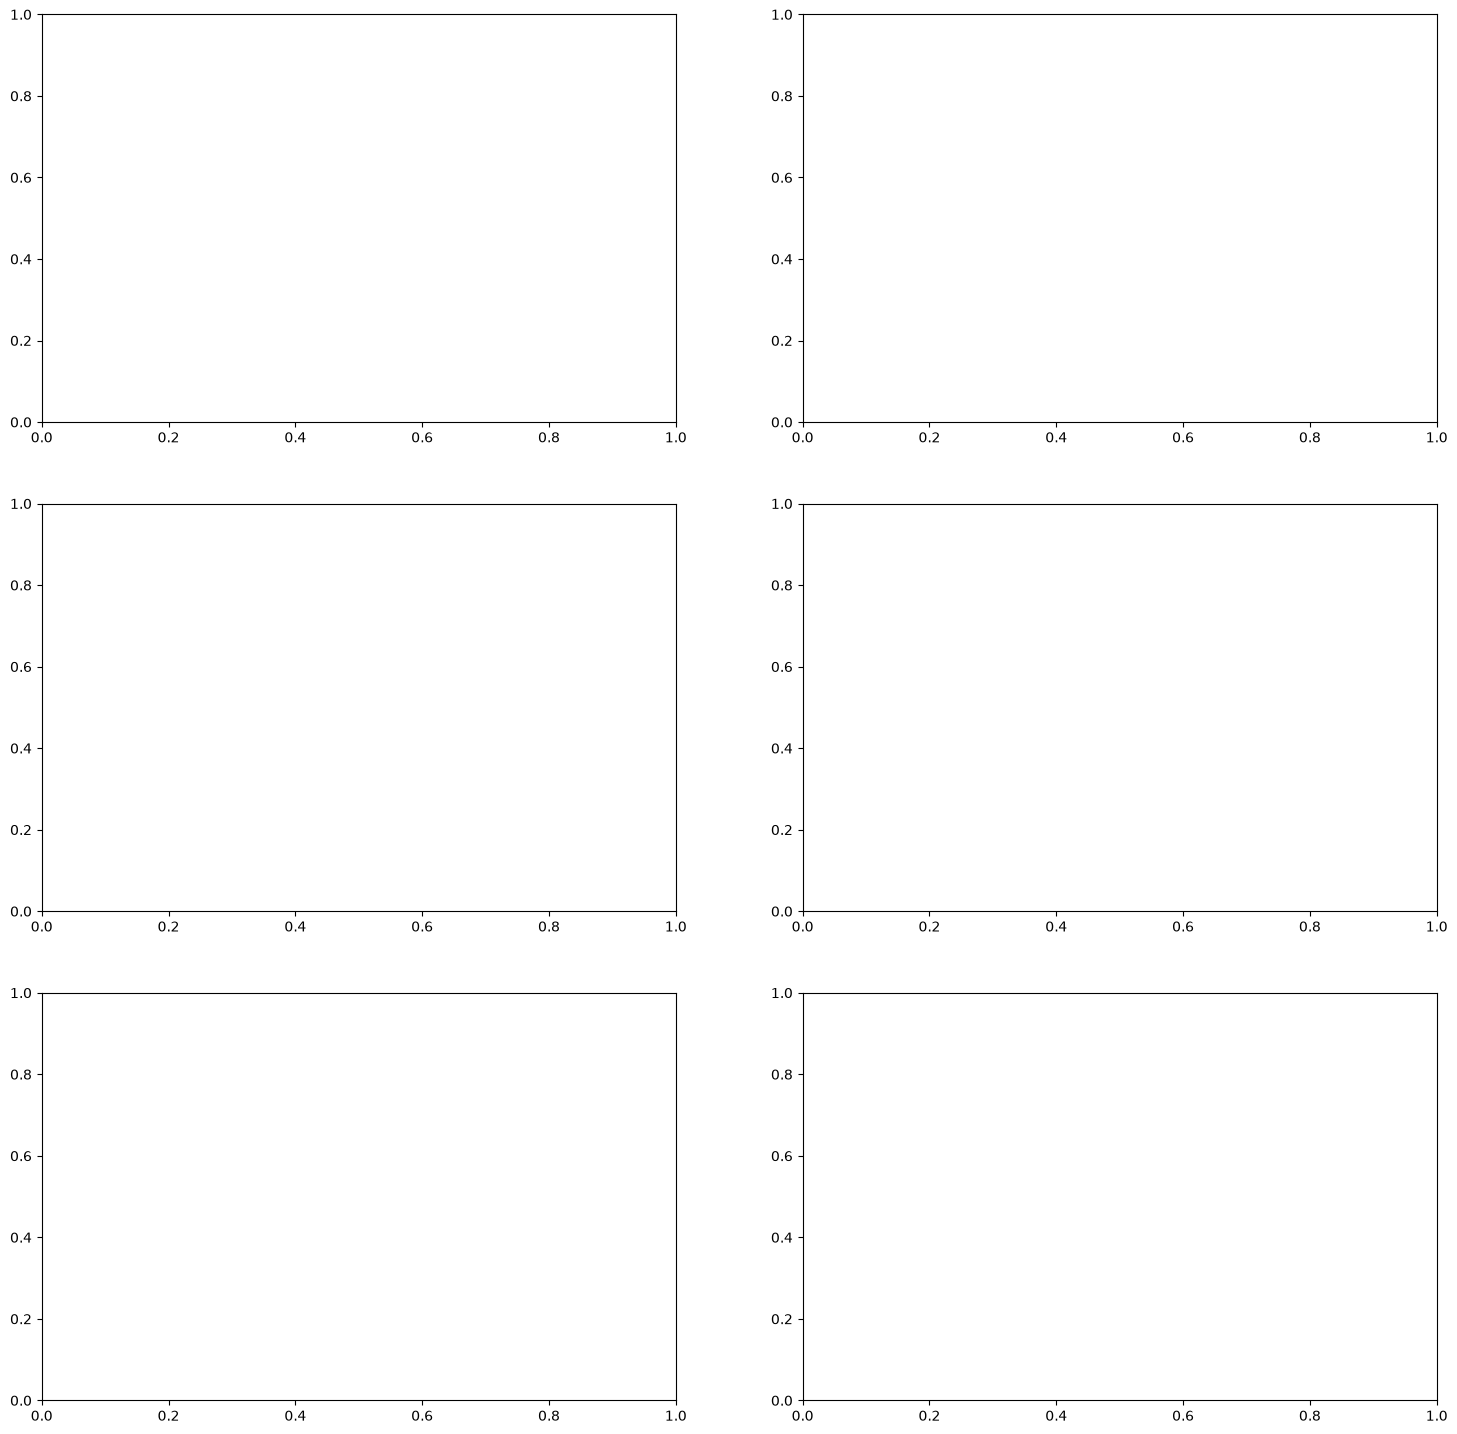

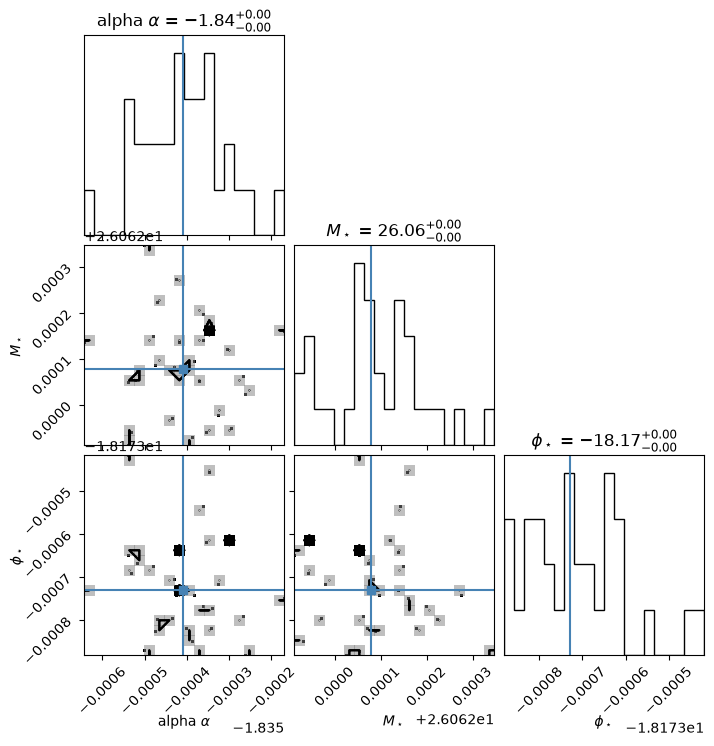

Reduced chi squared = 4.740
Fitted parameters: $\alpha$ = -1.835, $\log_10(M_\star/M_\odot)$ = 26.062, $\log_10(\phi_\star$ = -18.174
Guesses: alpha = -1.885, M_star = 9.119, phi_star = -4.373


100%|██████████| 5000/5000 [00:12<00:00, 409.54it/s]


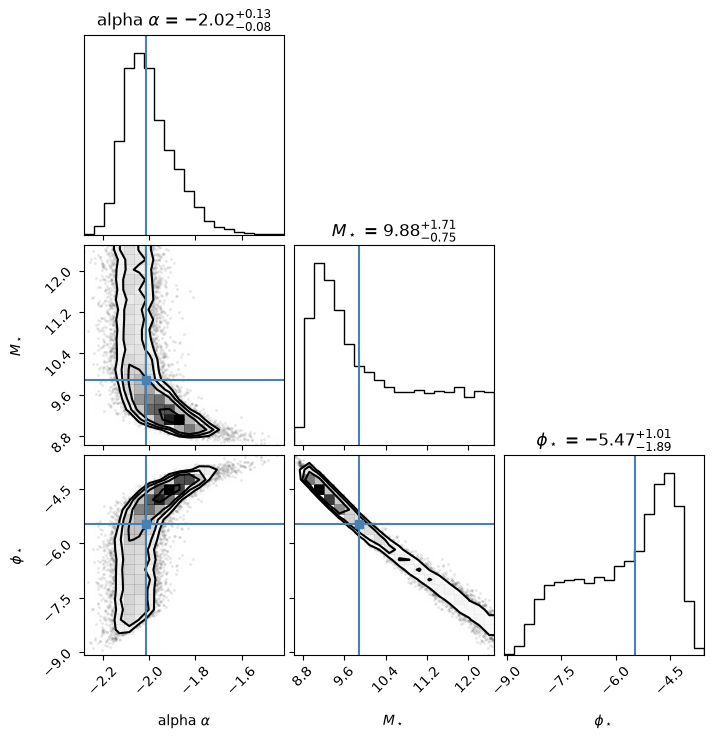

Reduced chi squared = 2.115
Fitted parameters: $\alpha$ = -2.015, $\log_10(M_\star/M_\odot)$ = 9.885, $\log_10(\phi_\star$ = -5.467
Guesses: alpha = -1.625, M_star = 9.017, phi_star = -4.370


100%|██████████| 5000/5000 [00:13<00:00, 373.61it/s]


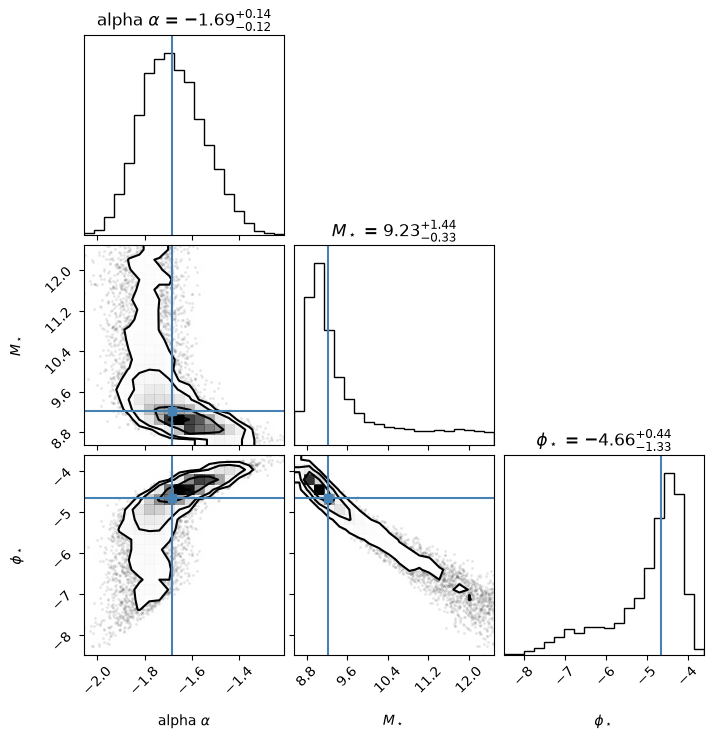

Reduced chi squared = 2.996
Fitted parameters: $\alpha$ = -1.686, $\log_10(M_\star/M_\odot)$ = 9.226, $\log_10(\phi_\star$ = -4.662
Guesses: alpha = -1.425, M_star = 9.243, phi_star = -4.059


100%|██████████| 5000/5000 [00:13<00:00, 383.41it/s]


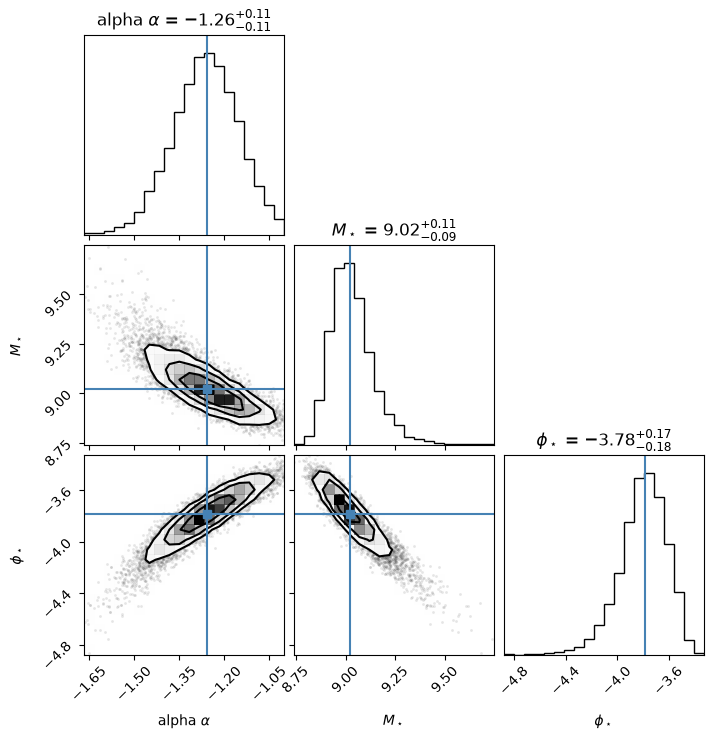

Reduced chi squared = 3.758
Fitted parameters: $\alpha$ = -1.259, $\log_10(M_\star/M_\odot)$ = 9.022, $\log_10(\phi_\star$ = -3.784
Guesses: alpha = -1.662, M_star = 9.934, phi_star = -5.206


100%|██████████| 5000/5000 [00:12<00:00, 389.79it/s]


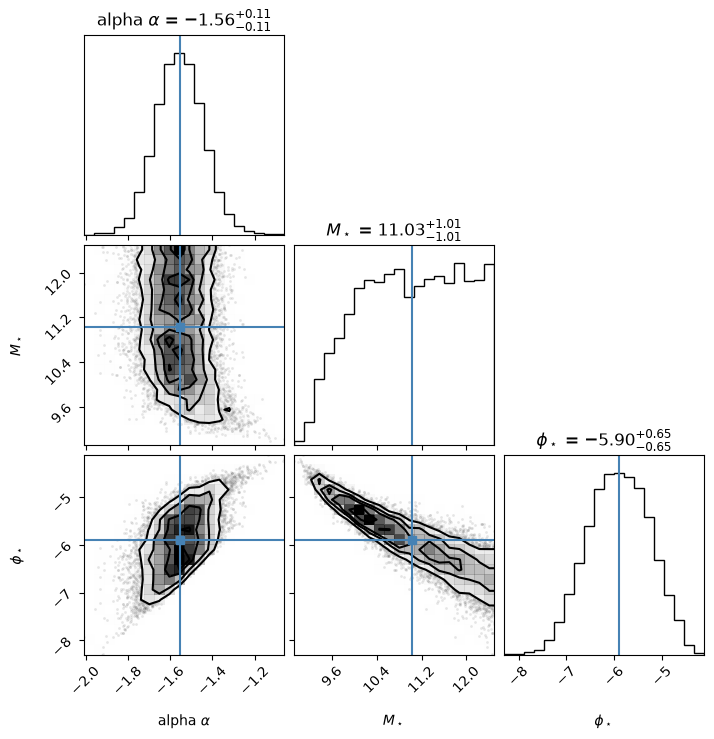

Reduced chi squared = 5.017
Fitted parameters: $\alpha$ = -1.555, $\log_10(M_\star/M_\odot)$ = 11.034, $\log_10(\phi_\star$ = -5.895


TypeError: plot_Muv_vs_Vmax() missing 1 required positional argument: 'n_mass_bins'

<Figure size 640x480 with 0 Axes>

In [140]:
if __name__ == "__main__":

    epochs_tables_path = "/raid/scratch/work/alberttg/Masters_project/Data_inputs/EPOCHS-v2_EPOCHS_good_EAZY_sfhz_blue_agn_zfree_MASTER_Sel-F277W+F356W+F444W_v12_psfmatch_F444W_empirical+v13_psfmatch_F444W_empirical+v14_psfmatch_F444W_empirical.fits"

    #epochs_table_path = "/raid/scratch/work/austind/GALFIND_WORK/Catalogues/v12_psfmatch_F444W_empirical+v13_psfmatch_F444W_empirical+v14_psfmatch_F444W_empirical/ACS_WFC+NIRCam/EPOCHS-v2_EPOCHS_good_EAZY_sfhz_blue_agn_zfree/(0.32)as/EPOCHS-v2_EPOCHS_good_EAZY_sfhz_blue_agn_zfree_MASTER_Sel-F277W+F356W+F444W_v12_psfmatch_F444W_empirical+v13_psfmatch_F444W_empirical+v14_psfmatch_F444W_empirical.fits""

    epochs_gold_sample_path = "/nvme/scratch/work/austind/EPOCHS-v2/tabs/EPOCHS-DR2_Austin26_cropped_with_zpdf.fits"

    sex_tab, bagpipes_zfix, bagpipes_zgauss, selection_tab, gold_sample = open_catalogue_data(epochs_tables_path, epochs_gold_sample_path)

    sample = masked_table(sex_tab, bagpipes_zfix, bagpipes_zgauss, selection_tab, gold_sample)

    sample_table_path = os.path.join(DATA_PRODUCTS_PATH, "First_sample_table.fits")
    sample.write(sample_table_path, format="fits", overwrite=True)

    #read_tom_data(f"harvey24.ecsv")

    #plot_stellar_mass_vs_redshift(sample)

    #plot_stellar_mass_vs_redshift_show_LRDs(sample)

    #plot_stellar_mass_vs_M_UV(sample)

    #approx_Vmax_method(sample)
    load_V_max_values(sample)

    simple_SMF_calculation(sample, n_mass_bins=8)

    plot_Muv_vs_Vmax(sample)

    sample_table_path = os.path.join(DATA_PRODUCTS_PATH, "First_sample_table.fits")
    sample.write(sample_table_path, format="fits", overwrite=True)